# Paper Analysis

Each Likert response is encoded as: strongly disagree = -2, disagree = -1, neutral = 0, agree = 1, strongly agree = 2. For each experiment e, model m, statement q, scenario c, and round r, a trajectory is the ordered response vector y(e,m,q,c) across five rounds.

Metrics used here:

- Within-question standard deviation: population SD of the trajectory across rounds.
- First-to-final displacement: absolute distance between the final and initial response.
- Cumulative deviation from the initial response: sum of absolute distances from the initial response over later rounds; this is not total movement between consecutive rounds.


In [15]:
from pathlib import Path
import io
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

try:
    from IPython.display import display, Image
except ImportError:
    Image = None
    def display(obj):
        return None

warnings.filterwarnings('ignore')

ROOT = Path.cwd()
FIG_DIR_PNG = ROOT / 'figures' / 'png'
FIG_DIR_PDF = ROOT / 'figures' / 'pdf'
FIG_DIR_PNG.mkdir(parents=True, exist_ok=True)
FIG_DIR_PDF.mkdir(parents=True, exist_ok=True)

SAVE_FIGURES = True
SHOW_FIGURES_INLINE = True
CLOSE_FIGURES_AFTER_RENDER = True

sns.set_theme(style='whitegrid', context='paper', font_scale=1.35)
plt.rcParams.update({
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'axes.titleweight': 'bold',
    'axes.labelsize': 15,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'legend.title_fontsize': 13,
    'axes.labelweight': 'bold',
    'font.family': 'DejaVu Sans',
})

EXPERIMENTS = [
    {'id': 'E1', 'name': 'Free summary', 'path': 'dados/experimento_1/respostas_iterativas.csv', 'intervention': 'summary'},
    {'id': 'E2', 'name': 'Summary protocol v2', 'path': 'dados/experimento_2/respostas_iterativas_v2.csv', 'intervention': 'summary v2'},
    {'id': 'E3', 'name': 'Trade-offs and uncertainty', 'path': 'dados/experimento_3/respostas_iterativas_v3.csv', 'intervention': 'structured summary'},
]
EXPERIMENT_ORDER = [meta['id'] for meta in EXPERIMENTS]
TENDENCY_LABELS = {'esquerda': 'Left', 'neutro': 'Neutral', 'direita': 'Right'}
FIGURE_EXPERIMENT_LABELS = {
    'E1': 'E1 — Free summary',
    'E2': 'E2 — Negative points and positive\npoints',
    'E3': 'E3 — Trade-offs and uncertainty',
}

from src.analysis.model_size_figure import MODEL_METADATA, SHORT_MODEL_NAMES

AXIS_SHORT_NAMES = {
    'Corrupção e Justiça': 'Corruption/justice',
    'Economia': 'Economy',
    'Educação e Cultura': 'Education/culture',
    'Instituições Democráticas': 'Democratic inst.',
    'Meio Ambiente': 'Environment',
    'Políticas Sociais': 'Social policy',
    'Segurança Pública': 'Public security',
}


In [16]:
def short_model_name(model):
    return SHORT_MODEL_NAMES.get(model, str(model).split('/')[-1].replace('-Instruct', '')[:22])


def finish_figure(fig, name):
    png = FIG_DIR_PNG / f'{name}.png'
    pdf = FIG_DIR_PDF / f'{name}.pdf'
    if SAVE_FIGURES:
        fig.savefig(png, bbox_inches='tight')
        fig.savefig(pdf, bbox_inches='tight')
        print(f'Saved {png.relative_to(ROOT)} and {pdf.relative_to(ROOT)}')
    if SHOW_FIGURES_INLINE and Image is not None:
        if SAVE_FIGURES:
            display(Image(filename=str(png)))
        else:
            buffer = io.BytesIO()
            fig.savefig(buffer, format='png', bbox_inches='tight')
            display(Image(data=buffer.getvalue()))
    if CLOSE_FIGURES_AFTER_RENDER:
        plt.close(fig)


def load_experiment(meta):
    df = pd.read_csv(ROOT / meta['path'])
    df['experiment'] = meta['id']
    df['experiment_name'] = meta['name']
    df['intervention'] = meta['intervention']
    df['rodada'] = pd.to_numeric(df.get('rodada', 1), errors='coerce').fillna(1).astype(int)
    df['likert_valor'] = pd.to_numeric(df.get('likert_valor'), errors='coerce')
    for col in ['modelo', 'provider', 'eixo', 'tipo_pergunta', 'pergunta', 'tendencia', 'pair_id', 'temperatura', 'repeticao']:
        if col not in df.columns:
            df[col] = np.nan
    df['condition'] = df['tendencia'].map(TENDENCY_LABELS).fillna(df['tendencia'])
    df['question_id'] = df['pair_id'].astype(str) + '|' + df['tipo_pergunta'].astype(str) + '|' + df['pergunta'].astype(str)
    return df


def build_round_level(valid):
    return (
        valid.groupby(
            ['experiment', 'experiment_name', 'intervention', 'modelo', 'condition', 'tendencia', 'eixo', 'question_id', 'rodada'],
            dropna=False,
        )['likert_valor']
        .mean()
        .reset_index()
        .sort_values(['experiment', 'modelo', 'condition', 'eixo', 'question_id', 'rodada'])
    )


def build_trajectories(round_level):
    rows = []
    group_cols = ['experiment', 'experiment_name', 'intervention', 'modelo', 'condition', 'tendencia', 'eixo', 'question_id']
    for keys, group in round_level.groupby(group_cols, dropna=False):
        ordered = group.sort_values('rodada')
        values = ordered['likert_valor'].to_numpy(dtype=float)
        rounds = ordered['rodada'].to_numpy(dtype=int)
        if len(values) == 0:
            continue
        diffs = np.diff(values)
        first = values[0]
        final = values[-1]
        rows.append({
            'experiment': keys[0],
            'experiment_name': keys[1],
            'intervention': keys[2],
            'modelo': keys[3],
            'condition': keys[4],
            'tendencia': keys[5],
            'eixo': keys[6],
            'question_id': keys[7],
            'n_rounds': len(np.unique(rounds)),
            'first_score': first,
            'final_score': final,
            'std': np.std(values, ddof=0),
            'variance': np.var(values, ddof=0),
            'any_change': float(len(np.unique(values)) > 1),
            'first_to_final_delta': final - first,
            'first_to_final_abs_delta': abs(final - first),
            'max_abs_shift_from_first': float(np.max(np.abs(values - first))),
            'cumulative_abs_shift_from_first': float(np.sum(np.abs(values[1:] - first))) if len(values) > 1 else 0.0,
            'mean_abs_step_change': float(np.mean(np.abs(diffs))) if len(diffs) else 0.0,
        })
    traj = pd.DataFrame(rows)
    return traj[traj['n_rounds'] > 1].copy()

def kruskal_epsilon_squared(h_stat, n, k):
    if pd.isna(h_stat) or n <= k:
        return np.nan
    return max(0.0, (h_stat - k + 1) / (n - k))


def kruskal_by_group(data, value_col, group_col):
    groups = [g[value_col].dropna().to_numpy() for _, g in data.groupby(group_col)]
    groups = [g for g in groups if len(g) > 0]
    if len(groups) < 2:
        return np.nan, np.nan, np.nan, sum(len(g) for g in groups), len(groups)
    h_stat, p_value = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    k = len(groups)
    return h_stat, p_value, kruskal_epsilon_squared(h_stat, n, k), n, k


def paired_wide_by_block(data, value_col, treatment_col, block_cols):
    if isinstance(block_cols, str):
        block_cols = [block_cols]
    wide = data.pivot_table(
        index=block_cols,
        columns=treatment_col,
        values=value_col,
        aggfunc='mean',
    )
    total_blocks = len(wide)
    wide = wide.dropna(axis=0, how='any')
    return wide, total_blocks


def friedman_kendall_w(chi2_stat, n_blocks, n_treatments):
    if pd.isna(chi2_stat) or n_blocks <= 0 or n_treatments <= 1:
        return np.nan
    return chi2_stat / (n_blocks * (n_treatments - 1))


def friedman_by_block(data, value_col, treatment_col, block_cols):
    wide, total_blocks = paired_wide_by_block(data, value_col, treatment_col, block_cols)
    n_blocks, n_treatments = wide.shape
    if n_blocks < 2 or n_treatments < 2:
        return np.nan, np.nan, np.nan, n_blocks, n_treatments, total_blocks
    chi2_stat, p_value = stats.friedmanchisquare(
        *[wide[col].to_numpy(dtype=float) for col in wide.columns]
    )
    kendall_w = friedman_kendall_w(chi2_stat, n_blocks, n_treatments)
    return chi2_stat, p_value, kendall_w, n_blocks, n_treatments, total_blocks


def holm_adjust_pvalues(p_values):
    p_values = np.asarray(p_values, dtype=float)
    adjusted = np.full_like(p_values, np.nan, dtype=float)
    valid = np.where(~np.isnan(p_values))[0]
    if len(valid) == 0:
        return adjusted
    ordered = valid[np.argsort(p_values[valid])]
    running_max = 0.0
    m = len(ordered)
    for rank, idx in enumerate(ordered):
        adj = min(1.0, (m - rank) * p_values[idx])
        running_max = max(running_max, adj)
        adjusted[idx] = running_max
    return adjusted


In [17]:
responses = pd.concat([load_experiment(meta) for meta in EXPERIMENTS], ignore_index=True)
valid = responses.dropna(subset=['likert_valor']).copy()
round_level = build_round_level(valid)
trajectories = build_trajectories(round_level)

print(f'Loaded rows: {len(responses):,}')
print(f'Valid Likert rows: {len(valid):,}')
print(f'Multi-round trajectories: {len(trajectories):,}')


Loaded rows: 50,370
Valid Likert rows: 50,234
Multi-round trajectories: 10,078


In [26]:
def plot_figure_2(traj):
    model_order = traj.groupby('modelo')['std'].mean().sort_values(ascending=True).index.tolist()
    label_order = [short_model_name(m) for m in model_order]
    plot_data = traj.copy()
    plot_data['model_short'] = plot_data['modelo'].map(dict(zip(model_order, label_order)))

    fig, axes = plt.subplots(len(EXPERIMENT_ORDER), 1, figsize=(12, 5.4 * len(EXPERIMENT_ORDER)), sharex=True)
    axes = np.atleast_1d(axes)
    for ax, exp in zip(axes, EXPERIMENT_ORDER):
        sub = plot_data[plot_data['experiment'] == exp]
        sns.boxplot(
            data=sub,
            y='model_short',
            x='std',
            order=label_order,
            color='#d9e8f5',
            fliersize=2.5,
            linewidth=1.2,
            medianprops={'color': '#b91c1c', 'linewidth': 3.0},
            ax=ax,
        )
        ax.set_title(FIGURE_EXPERIMENT_LABELS[exp], fontsize=15, fontweight='bold')
        ax.set_xlabel('Within-question SD across rounds (0 = unchanged)')
        ax.set_ylabel('Model')
        ax.grid(axis='x', alpha=.25)
    plt.tight_layout()
    finish_figure(fig, 'figure_2')


def plot_figure_3(traj):
    from src.analysis.model_size_figure import create_model_size_figures

    global model_size_stats_table, model_size_leave_one_out
    model_size_stats_table, model_size_leave_one_out = create_model_size_figures(
        traj,
        ROOT,
        save_leave_one_out_figure=True,
    )
    display(model_size_stats_table)
    display(model_size_leave_one_out)

def plot_figure_4(traj):
    tests = []
    for (exp, condition), sub in traj.groupby(['experiment', 'condition']):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'std', 'modelo')
        tests.append({'experiment': exp, 'condition': condition, 'p_value': p_value, 'significant': bool(p_value < .05) if not pd.isna(p_value) else False})
    sig_lookup = pd.DataFrame(tests).set_index(['experiment', 'condition'])['significant'].to_dict()

    standard_deviation_landscape = (
        traj.groupby(['experiment', 'condition', 'modelo'], as_index=False)
        .agg(mean_standard_deviation=('std', 'mean'))
    )
    standard_deviation_landscape['model_short'] = standard_deviation_landscape['modelo'].map(SHORT_MODEL_NAMES).fillna(standard_deviation_landscape['modelo'].str.split('/').str[-1].str[:18])
    condition_order = [c for c in ['Left', 'Neutral', 'Right'] if c in set(standard_deviation_landscape['condition'])]
    column_order = [(exp, cond) for exp in EXPERIMENT_ORDER for cond in condition_order]
    column_labels = []
    for exp, cond in column_order:
        star = '*' if sig_lookup.get((exp, cond), False) else ''
        cond_label = 'no-context' if cond == 'Neutral' else cond
        column_labels.append(f'{exp}\n{cond_label}{star}')
    standard_deviation_landscape['column_key'] = standard_deviation_landscape.apply(lambda r: f"{r['experiment']}|{r['condition']}", axis=1)
    ordered_keys = [f'{exp}|{cond}' for exp, cond in column_order]
    heat = standard_deviation_landscape.pivot_table(index='model_short', columns='column_key', values='mean_standard_deviation', aggfunc='mean').reindex(columns=ordered_keys)
    row_order = heat.mean(axis=1).sort_values(ascending=False).index
    heat = heat.loc[row_order]
    heat.columns = column_labels
    bar_values = heat.mean(axis=1)

    fig = plt.figure(figsize=(17.0, max(6.2, .42 * len(heat))))
    gs = fig.add_gridspec(1, 2, width_ratios=[5.5, 1.25], wspace=.08)
    ax_heat = fig.add_subplot(gs[0, 0])
    ax_bar = fig.add_subplot(gs[0, 1], sharey=ax_heat)
    sns.heatmap(heat, cmap='rocket_r', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean within-question standard deviation'}, ax=ax_heat)
    ax_heat.set_xlabel('')
    ax_heat.set_ylabel('Model')
    ax_heat.tick_params(axis='x', rotation=0)
    ax_bar.barh(np.arange(len(row_order)) + .5, bar_values, height=.72, color='#475569')
    ax_bar.set_xlabel('Row\nmean')
    ax_bar.set_ylabel('')
    ax_bar.grid(axis='x', alpha=.25)
    ax_bar.tick_params(axis='y', left=False, labelleft=False)
    ax_bar.invert_yaxis()
    for y, value in enumerate(bar_values):
        ax_bar.text(value + .01, y + .5, f'{value:.2f}', va='center', fontsize=11)
    fig.subplots_adjust(bottom=.08, top=.96)
    finish_figure(fig, 'figure_4')


def plot_figure_5(traj):
    axis_summary = (
        traj.groupby(['experiment', 'eixo'], as_index=False)
        .agg(mean_abs_displacement=('first_to_final_abs_delta', 'mean'))
    )
    axis_agg = traj.groupby('eixo', as_index=False).agg(mean_abs_displacement=('first_to_final_abs_delta', 'mean'))
    axis_agg['experiment'] = 'Aggregated'
    axis_plot = pd.concat([axis_summary, axis_agg], ignore_index=True)
    axis_plot['axis_short'] = axis_plot['eixo'].map(AXIS_SHORT_NAMES).fillna(axis_plot['eixo'])
    heat = axis_plot.pivot_table(index='axis_short', columns='experiment', values='mean_abs_displacement').reindex(columns=EXPERIMENT_ORDER + ['Aggregated'])
    heat = heat.loc[heat['Aggregated'].sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8.8, max(4.8, .5 * len(heat))))
    sns.heatmap(heat, cmap='mako_r', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean absolute displacement'}, ax=ax)
    ax.set_xlabel('Experiment')
    ax.set_ylabel('Issue axis')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    finish_figure(fig, 'figure_5')


def plot_figure_6(traj):
    cumulative = traj.copy()
    cumulative['model_short'] = cumulative['modelo'].map(SHORT_MODEL_NAMES).fillna(cumulative['modelo'].str.split('/').str[-1].str[:18])
    model_experiment = (
        cumulative.groupby(['experiment', 'modelo', 'model_short'], as_index=False)
        .agg(mean_cumulative_shift=('cumulative_abs_shift_from_first', 'mean'))
    )
    model_agg = cumulative.groupby(['modelo', 'model_short'], as_index=False).agg(mean_cumulative_shift=('cumulative_abs_shift_from_first', 'mean'))
    model_agg['experiment'] = 'Aggregated'
    cum_plot = pd.concat([model_experiment, model_agg], ignore_index=True)
    heat = cum_plot.pivot_table(index='model_short', columns='experiment', values='mean_cumulative_shift').reindex(columns=EXPERIMENT_ORDER + ['Aggregated'])
    heat = heat.loc[heat['Aggregated'].sort_values(ascending=False).index]
    fig, ax = plt.subplots(figsize=(8.6, max(5.4, .5 * len(heat))))
    sns.heatmap(heat, cmap='flare', annot=True, annot_kws={'fontsize': 13}, fmt='.2f', linewidths=.5, cbar_kws={'label': 'Mean cumulative deviation\nfrom initial response'}, ax=ax)
    ax.set_xlabel('Experiment')
    ax.set_ylabel('Model')
    ax.tick_params(axis='x', rotation=0)
    plt.tight_layout()
    finish_figure(fig, 'figure_6')


def build_likert_transition_matrix(round_data, experiment=None):
    sub = round_data.copy()
    if experiment is not None:
        sub = sub[sub['experiment'] == experiment].copy()

    likert_values = [-2, -1, 0, 1, 2]
    rows = []
    group_cols = ['experiment', 'modelo', 'condition', 'eixo', 'question_id']
    for _, group in sub.groupby(group_cols, dropna=False):
        ordered = group.sort_values('rodada')
        values = ordered['likert_valor'].to_numpy(dtype=float)
        values = [int(v) for v in values if not pd.isna(v)]
        for from_score, to_score in zip(values[:-1], values[1:]):
            if from_score in likert_values and to_score in likert_values:
                rows.append({'from_score': from_score, 'to_score': to_score})

    if rows:
        transitions = pd.DataFrame(rows)
        counts = pd.crosstab(transitions['from_score'], transitions['to_score'])
    else:
        counts = pd.DataFrame(0, index=likert_values, columns=likert_values)
    counts = counts.reindex(index=likert_values, columns=likert_values, fill_value=0)
    row_totals = counts.sum(axis=1).replace(0, np.nan)
    probabilities = counts.div(row_totals, axis=0).fillna(0.0)
    return probabilities, counts


def plot_figure_7(round_data):
    likert_tick_labels = ['Strongly\ndisagree', 'Disagree', 'Neutral', 'Agree', 'Strongly\nagree']
    panels = [(exp, FIGURE_EXPERIMENT_LABELS[exp].replace('\n', ' ')) for exp in EXPERIMENT_ORDER]
    panels.append((None, 'Aggregated'))

    fig = plt.figure(figsize=(13.8, 9.2))
    gs = fig.add_gridspec(
        2,
        3,
        width_ratios=[1, 1, 0.055],
        wspace=.14,
        hspace=.42,
        left=.095,
        right=.92,
        bottom=.17,
        top=.94,
    )
    axes = np.array([
        fig.add_subplot(gs[0, 0]),
        fig.add_subplot(gs[0, 1]),
        fig.add_subplot(gs[1, 0]),
        fig.add_subplot(gs[1, 1]),
    ])
    cbar_ax = fig.add_subplot(gs[:, 2])
    heatmap_mappable = None

    for ax, (exp, title) in zip(axes, panels):
        probabilities, counts = build_likert_transition_matrix(round_data, experiment=exp)
        annot = probabilities.map(lambda value: f'{100 * value:.0f}%')
        sns.heatmap(
            probabilities,
            cmap='viridis',
            vmin=0,
            vmax=1,
            annot=annot,
            fmt='',
            annot_kws={'fontsize': 13},
            linewidths=.5,
            linecolor='white',
            cbar=False,
            ax=ax,
        )
        if heatmap_mappable is None:
            heatmap_mappable = ax.collections[0]
        ax.set_title(f'{title}', fontsize=13, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_xticklabels(likert_tick_labels, rotation=35, ha='right')
        ax.set_yticklabels(likert_tick_labels, rotation=0)
        if ax in axes[:2]:
            ax.tick_params(axis='x', labelbottom=False)
        if ax in axes[[1, 3]]:
            ax.tick_params(axis='y', labelleft=False)

    colorbar = fig.colorbar(heatmap_mappable, cax=cbar_ax)
    colorbar.set_label('Transition probability', fontsize=13, fontweight='bold')
    cbar_ax.tick_params(labelsize=11)
    fig.text(0.5, .04, 'Next-round Likert category', ha='center', va='center', fontsize=15, fontweight='bold')
    fig.text(0.02, 0.52, 'Current-round Likert category', ha='center', va='center', rotation='vertical', fontsize=15, fontweight='bold')
    finish_figure(fig, 'figure_7')



Saved figures/png/figure_7.png and figures/pdf/figure_7.pdf


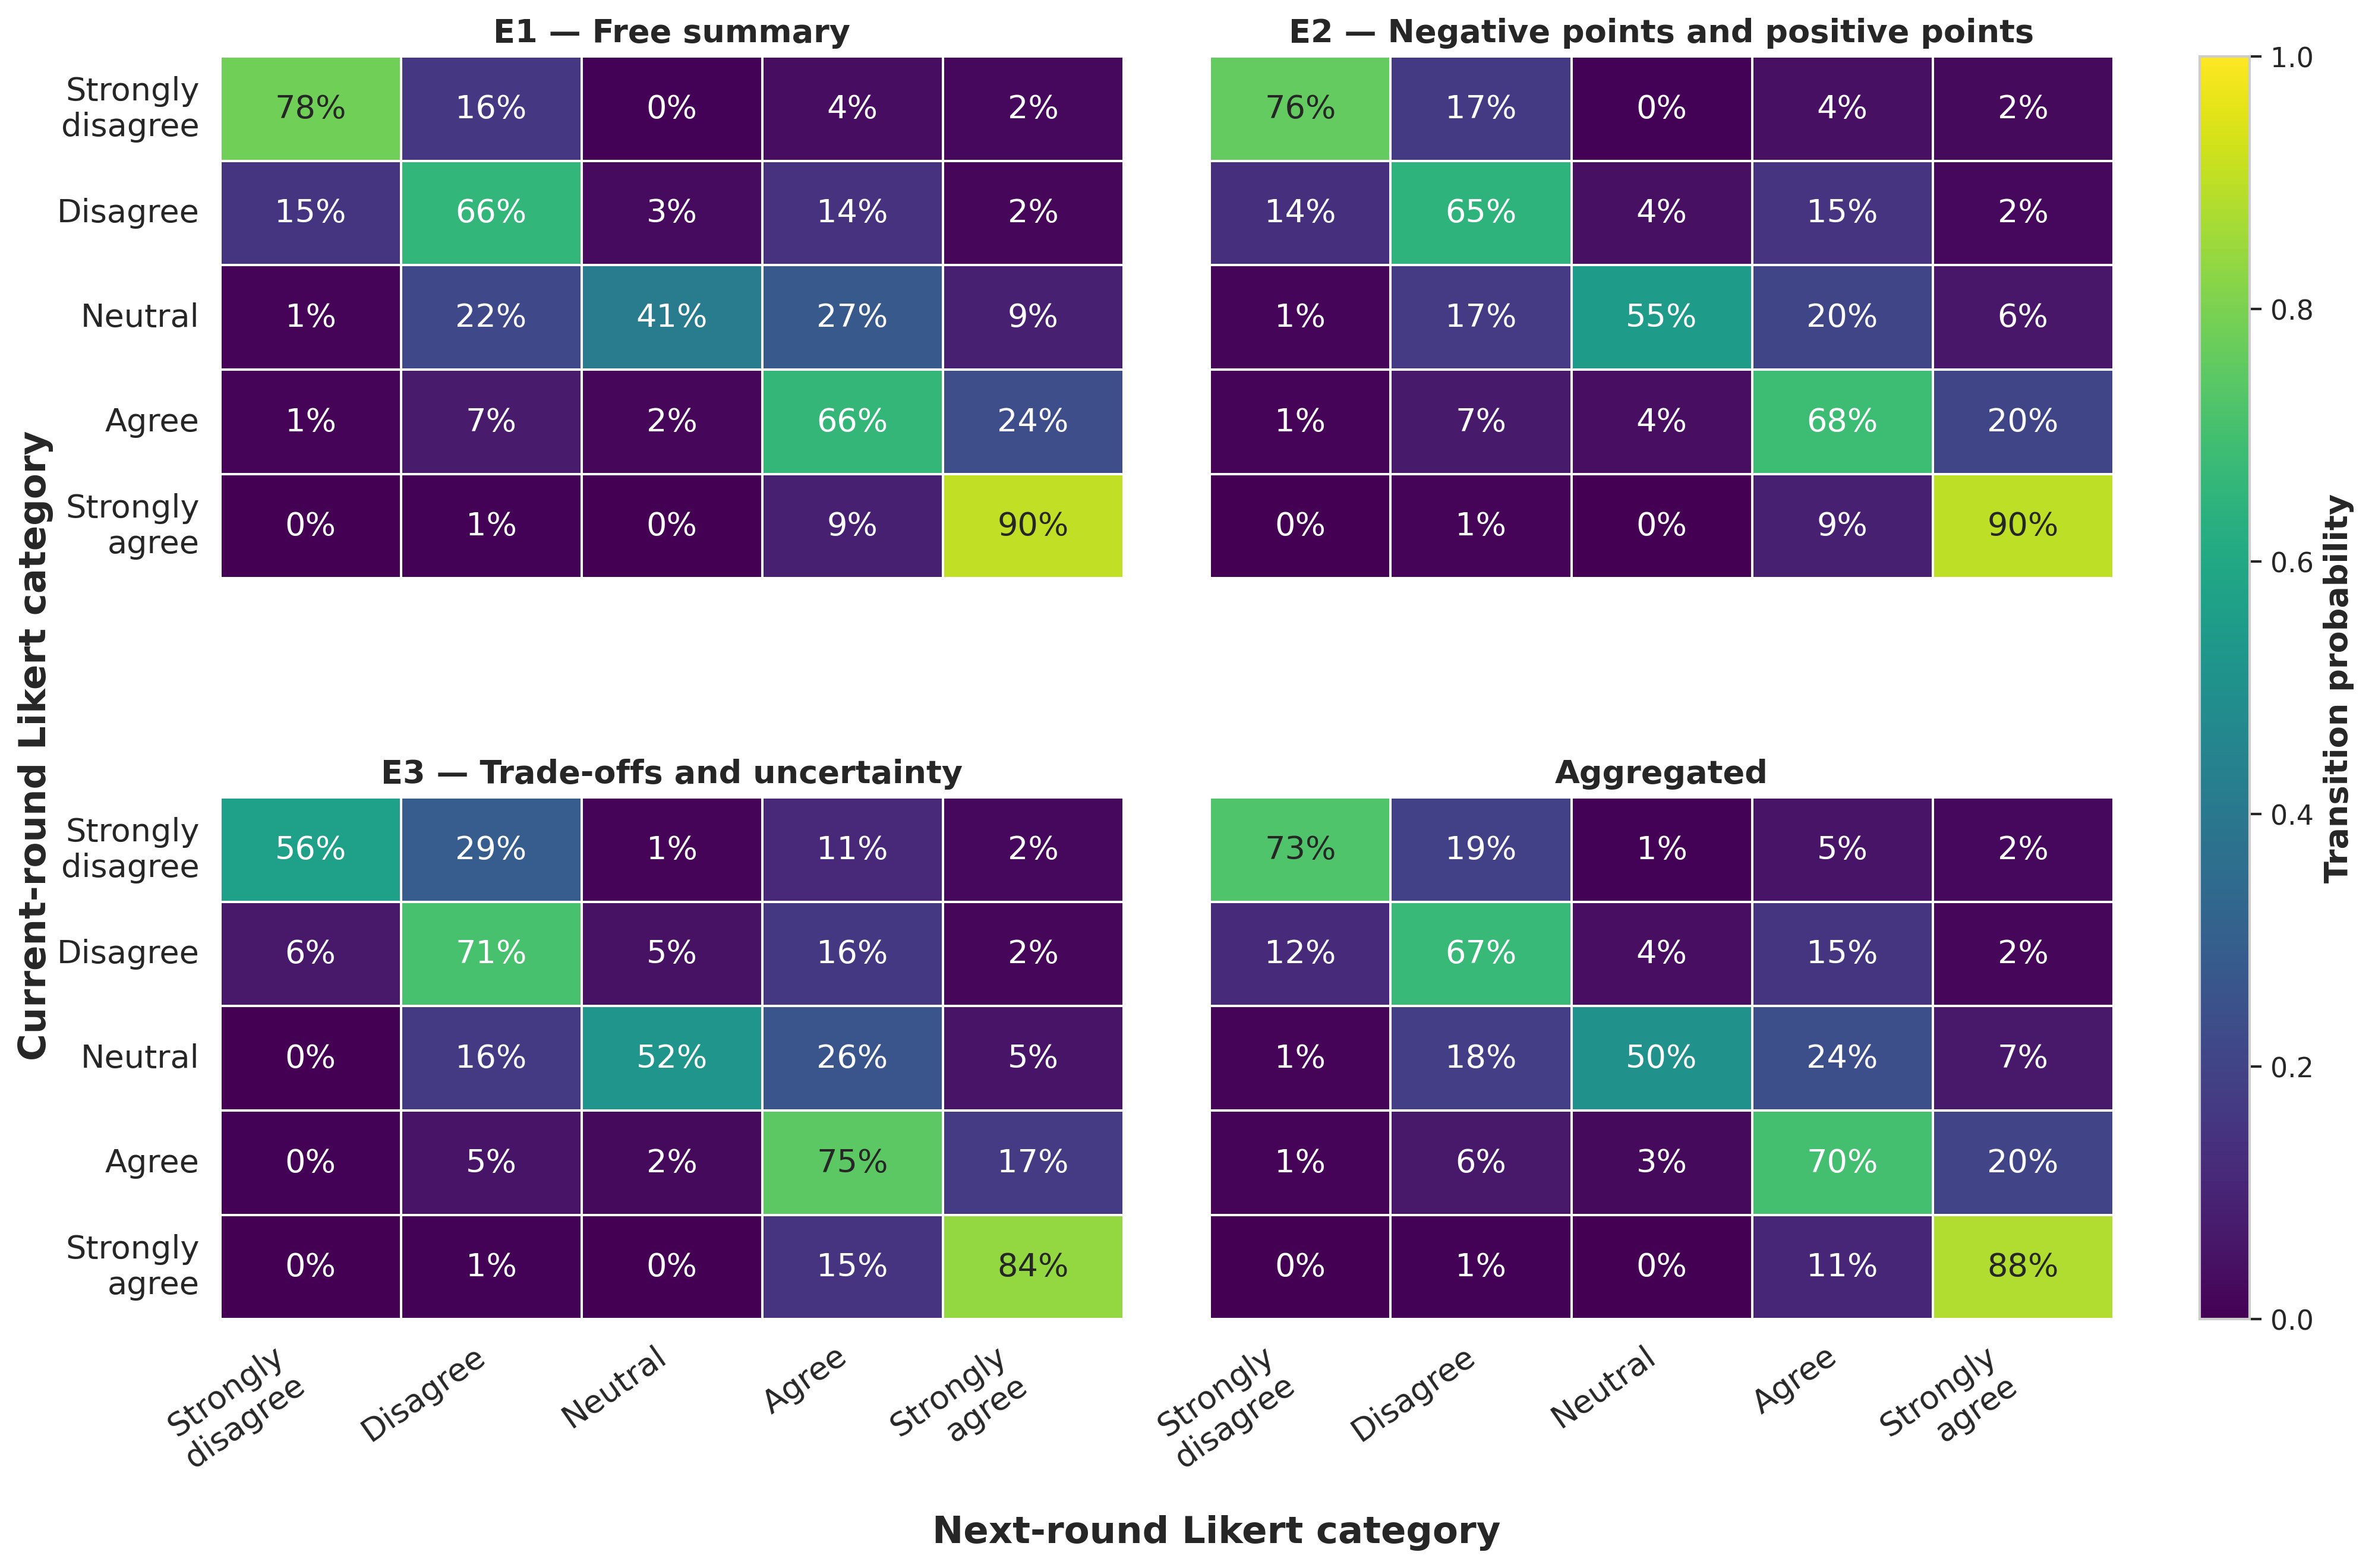

In [27]:
# plot_figure_2(trajectories)
# plot_figure_3(trajectories)
# plot_figure_4(trajectories)
# plot_figure_5(trajectories)
# plot_figure_6(trajectories)

plot_figure_7(round_level)


## Statistical Results for the Paper Text

The cells below generate the Kruskal-Wallis tests, epsilon squared effect sizes, Dunn-Holm pairwise checks, and parameter-count correlations reported in the Results section.


In [13]:
def model_stability_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'std', 'modelo')
        rows.append({
            'experiment': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values('experiment')


def model_stability_friedman_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        chi2, p_value, kendall_w, n_blocks, k, total_blocks = friedman_by_block(
            sub,
            value_col='std',
            treatment_col='modelo',
            block_cols=['condition', 'eixo', 'question_id'],
        )
        rows.append({
            'experiment': exp,
            'friedman_chi2': chi2,
            'p': p_value,
            'kendall_w': kendall_w,
            'complete_blocks': n_blocks,
            'total_blocks': total_blocks,
            'dropped_blocks': total_blocks - n_blocks,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values('experiment')


def model_stability_wilcoxon_holm(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        wide, total_blocks = paired_wide_by_block(
            sub,
            value_col='std',
            treatment_col='modelo',
            block_cols=['condition', 'eixo', 'question_id'],
        )
        if wide.shape[1] < 2 or len(wide) < 2:
            continue
        med = wide.median(axis=0).sort_values()
        best_model = med.index[0]
        comparisons = []
        p_values = []
        for model in med.index[1:]:
            try:
                stat, p_value = stats.wilcoxon(
                    wide[best_model].to_numpy(dtype=float),
                    wide[model].to_numpy(dtype=float),
                    zero_method='zsplit',
                )
            except ValueError:
                stat, p_value = np.nan, np.nan
            comparisons.append((model, stat, p_value))
            p_values.append(p_value)
        adjusted = holm_adjust_pvalues(p_values)
        for (model, stat, p_value), adj_p in zip(comparisons, adjusted):
            rows.append({
                'experiment': exp,
                'most_stable_model': short_model_name(best_model),
                'comparison_model': short_model_name(model),
                'most_stable_median_sd': med.loc[best_model],
                'comparison_median_sd': med.loc[model],
                'wilcoxon_stat': stat,
                'raw_p': p_value,
                'holm_adjusted_p': adj_p,
                'complete_blocks': len(wide),
                'total_blocks': total_blocks,
                'significant_at_0_05': bool(adj_p < .05) if not pd.isna(adj_p) else False,
            })
    return pd.DataFrame(rows)


def model_stability_dunn_holm(traj):
    try:
        import scikit_posthocs as sp
    except ImportError:
        return pd.DataFrame({'note': ['scikit_posthocs is not installed; Dunn-Holm table was not generated.']})

    rows = []
    for exp, sub in traj.groupby('experiment'):
        med = sub.groupby('modelo')['std'].median().sort_values()
        best_model = med.index[0]
        pmat = sp.posthoc_dunn(sub, val_col='std', group_col='modelo', p_adjust='holm')
        for model in med.index[1:]:
            rows.append({
                'experiment': exp,
                'most_stable_model': short_model_name(best_model),
                'comparison_model': short_model_name(model),
                'most_stable_median_sd': med.loc[best_model],
                'comparison_median_sd': med.loc[model],
                'holm_adjusted_p': float(pmat.loc[best_model, model]),
                'significant_at_0_05': bool(pmat.loc[best_model, model] < .05),
            })
    return pd.DataFrame(rows)


def scenario_variance_tests(traj):
    rows = []
    for (exp, condition), sub in traj.groupby(['experiment', 'condition']):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'std', 'modelo')
        rows.append({
            'experiment': exp,
            'scenario': 'no-context' if condition == 'Neutral' else condition,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values(['experiment', 'scenario'])


def scenario_variance_friedman_tests(traj):
    rows = []
    for (exp, condition), sub in traj.groupby(['experiment', 'condition']):
        chi2, p_value, kendall_w, n_blocks, k, total_blocks = friedman_by_block(
            sub,
            value_col='std',
            treatment_col='modelo',
            block_cols=['eixo', 'question_id'],
        )
        rows.append({
            'experiment': exp,
            'scenario': 'no-context' if condition == 'Neutral' else condition,
            'friedman_chi2': chi2,
            'p': p_value,
            'kendall_w': kendall_w,
            'complete_blocks': n_blocks,
            'total_blocks': total_blocks,
            'dropped_blocks': total_blocks - n_blocks,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    return pd.DataFrame(rows).sort_values(['experiment', 'scenario'])


def scenario_pvalue_table(scenario_tests):
    order = ['Left', 'no-context', 'Right']
    return (
        scenario_tests.pivot(index='experiment', columns='scenario', values='p')
        .reindex(index=EXPERIMENT_ORDER, columns=order)
        .reset_index()
    )


def parameter_count_correlations(traj):
    from src.analysis.model_size_figure import compute_model_size_statistics

    stats_table, _ = compute_model_size_statistics(traj)
    return stats_table


def model_size_leave_one_out_table(traj):
    from src.analysis.model_size_figure import compute_model_size_statistics

    _, leave_one_out = compute_model_size_statistics(traj)
    return leave_one_out


def issue_axis_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'first_to_final_abs_delta', 'eixo')
        rows.append({
            'scope': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_issue_axes': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    h_stat, p_value, eps2, n, k = kruskal_by_group(traj, 'first_to_final_abs_delta', 'eixo')
    rows.append({
        'scope': 'Aggregated',
        'H': h_stat,
        'p': p_value,
        'epsilon_squared': eps2,
        'n_trajectories': n,
        'n_issue_axes': k,
        'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
    })
    return pd.DataFrame(rows)


def cumulative_shift_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        h_stat, p_value, eps2, n, k = kruskal_by_group(sub, 'cumulative_abs_shift_from_first', 'modelo')
        rows.append({
            'scope': exp,
            'H': h_stat,
            'p': p_value,
            'epsilon_squared': eps2,
            'n_trajectories': n,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    h_stat, p_value, eps2, n, k = kruskal_by_group(traj, 'cumulative_abs_shift_from_first', 'modelo')
    rows.append({
        'scope': 'Aggregated',
        'H': h_stat,
        'p': p_value,
        'epsilon_squared': eps2,
        'n_trajectories': n,
        'n_models': k,
        'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
    })
    return pd.DataFrame(rows)


def cumulative_shift_friedman_tests(traj):
    rows = []
    for exp, sub in traj.groupby('experiment'):
        chi2, p_value, kendall_w, n_blocks, k, total_blocks = friedman_by_block(
            sub,
            value_col='cumulative_abs_shift_from_first',
            treatment_col='modelo',
            block_cols=['condition', 'eixo', 'question_id'],
        )
        rows.append({
            'scope': exp,
            'friedman_chi2': chi2,
            'p': p_value,
            'kendall_w': kendall_w,
            'complete_blocks': n_blocks,
            'total_blocks': total_blocks,
            'dropped_blocks': total_blocks - n_blocks,
            'n_models': k,
            'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
        })
    chi2, p_value, kendall_w, n_blocks, k, total_blocks = friedman_by_block(
        traj,
        value_col='cumulative_abs_shift_from_first',
        treatment_col='modelo',
        block_cols=['experiment', 'condition', 'eixo', 'question_id'],
    )
    rows.append({
        'scope': 'Aggregated',
        'friedman_chi2': chi2,
        'p': p_value,
        'kendall_w': kendall_w,
        'complete_blocks': n_blocks,
        'total_blocks': total_blocks,
        'dropped_blocks': total_blocks - n_blocks,
        'n_models': k,
        'significant_at_0_05': bool(p_value < .05) if not pd.isna(p_value) else False,
    })
    return pd.DataFrame(rows)


In [14]:
model_tests = model_stability_tests(trajectories)
model_friedman = model_stability_friedman_tests(trajectories)
wilcoxon_holm = model_stability_wilcoxon_holm(trajectories)
dunn_holm = model_stability_dunn_holm(trajectories)
scenario_tests = scenario_variance_tests(trajectories)
scenario_friedman = scenario_variance_friedman_tests(trajectories)
scenario_pvalues = scenario_pvalue_table(scenario_tests)
scenario_friedman_pvalues = scenario_pvalue_table(scenario_friedman)
size_correlations = parameter_count_correlations(trajectories)
model_size_leave_one_out = model_size_leave_one_out_table(trajectories)
axis_tests = issue_axis_tests(trajectories)
cum_tests = cumulative_shift_tests(trajectories)
cum_friedman = cumulative_shift_friedman_tests(trajectories)

print('Model-level stability Friedman tests')
display(model_friedman)

print('Wilcoxon-Holm paired checks against the lowest-median-SD model')
display(wilcoxon_holm)

print('Model-level stability Kruskal-Wallis sensitivity tests')
display(model_tests)

print('Dunn-Holm unpaired sensitivity checks against the lowest-median-SD model')
display(dunn_holm)

print('Scenario-specific standard deviation Friedman tests')
display(scenario_friedman)

print('Scenario-specific Friedman p-value table')
display(scenario_friedman_pvalues)

print('Scenario-specific standard deviation Kruskal-Wallis sensitivity tests')
display(scenario_tests)

print('Scenario-specific Kruskal-Wallis p-value table')
display(scenario_pvalues)

print('Parameter-count correlations: active and total parameter scales')
display(size_correlations)

print('Leave-one-out sensitivity: aggregated active-parameter correlation')
display(model_size_leave_one_out)

print('Issue-axis Kruskal-Wallis tests')
display(axis_tests)

print('Cumulative-deviation Friedman tests')
display(cum_friedman)

print('Cumulative-deviation Kruskal-Wallis sensitivity tests')
display(cum_tests)


KeyboardInterrupt: 